# Model optimization: V2 development validation

See `docs/evaluation_protocol.md` for chronology, eligibility and caveats.
The existing V1 notebooks are unchanged. This notebook analyzes executed runs;
rerun `python scripts/run_experiments.py` to refit models. NDCG@10 selects family
winners; lower accuracy variants are retained as negative findings.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import joblib
ROOT = Path.cwd() if (Path.cwd() / 'reports').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
results = pd.read_csv(ROOT / 'reports/results/validation_all_runs.csv')
bundle = joblib.load(ROOT / 'artifacts/recommenders.joblib')


In [2]:
display(results[results.family.isin(['Content_V1','Content_V2','User_V1','User_V2','User_V3','Item_V1','Item_V2'])][['model','hyperparameters','Hit Rate@10','NDCG@10','Coverage','Diversity']])

,model,hyperparameters,Hit Rate@10,NDCG@10,Coverage,Diversity
2,Content_V1,"{""weighted"": false}",0.054,0.015953,0.714715,0.700148
3,Content_weighted,"{""weighted"": true}",0.051,0.014773,0.773774,0.728331
4,Content_bigrams,"{""ngrams"": 2, ""weighted"": true}",0.053,0.015085,0.810811,0.752185
5,Content_negative,"{""negative"": true, ""weighted"": true}",0.052,0.014745,0.787788,0.728141
6,Content_MMR,"{""rerank"": true, ""weighted"": true}",0.047,0.013355,0.872873,0.841824
7,User_V1,"{""axis"": ""user"", ""k"": 30}",0.070,0.027395,0.824825,0.933518
8,User_V2,"{""axis"": ""user"", ""k"": 30, ""reg"": 2, ""support"": 2}",0.087,0.028403,0.721722,0.922382
9,Item_V1,"{""axis"": ""item"", ""k"": 30, ""reg"": 2}",0.097,0.030920,0.792793,0.900170
10,User_V3_0,"{""axis"": ""user"", ""k"": 10, ""min_common"": 2, ""re...",0.049,0.018218,0.722723,0.924642
11,User_V3_1,"{""axis"": ""user"", ""k"": 20, ""min_common"": 2, ""re...",0.073,0.024061,0.770771,0.926085


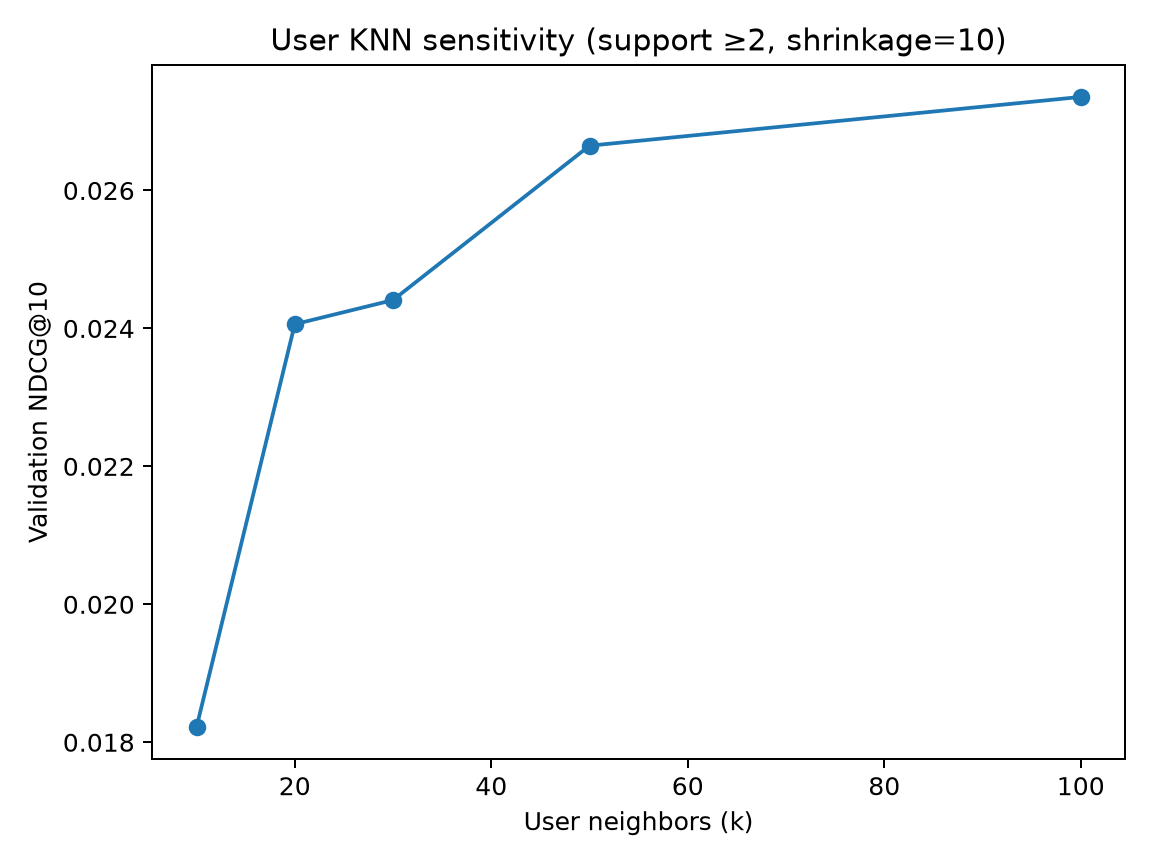

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'reports/figures/user_knn_sensitivity.png')))